# Studiul de caz 6 - Merită investiția într-o baterie? Prognoze probabilistice și arbitraj pe piața pentru ziua următoare

Energy MBA - Analiza cantitativă a piețelor de energie (EMQA) - Prof. Daniel Traian Pele

Academia de Studii Economice din București - Academia Română, Institutul de Prognoză Economică

In [ ]:
# Google Colab: copiem repo-ul cursului, ca datele și rezultatele salvate să fie găsite
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/EMQA'):
    if not os.path.isdir('/content/EMQA'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/EMQA.git', '/content/EMQA'], check=True)
    os.chdir('/content/EMQA/cases/C6_battery_arbitrage')

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "ro"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Lucrarea de referință.** Andrei, A.-V., Cepoi, C. O., Dumitrescu, B. A., Lessmann, S., Chiriac (Luchian), A.-C., Pele, D. T. și Petukhina, A. (2026).
Joint probabilistic forecasting for battery arbitrage in day-ahead power markets. SSRN, document de lucru 6872381. doi:10.2139/ssrn.6872381

**Conținutul notebook-ului.** O baterie de 1 MW / 1 MWh, cu randament de 90 %, efectuează cel mult un ciclu de încărcare-descărcare pe zi pe piața pentru ziua următoare (PZU) din România.
Comparăm trei moduri de alegere a orelor: previziunea perfectă (o limită superioară), o pereche fixă de ore și o regulă bazată pe prognoze
*probabilistice* ale celor 24 de prețuri din ziua următoare, obținute cu un model Random Forest. Calculăm apoi indicatorii de evaluare a investiției folosiți în lucrare (VAN, perioada de recuperare).

**Adaptarea pentru curs.** Lucrarea folosește modele DRF (*Distributional Random Forests*, în care ramificările sînt alese astfel încît să separe distribuții întregi), cu 37 de variabile
fundamentale, pentru România, Bulgaria, Ungaria și Cehia, ianuarie 2018 – septembrie 2024. Noi folosim un model Random Forest obișnuit, ale cărui ponderi din frunze conduc la o distribuție
comună a celor 24 de prețuri, numai cu prețuri anterioare și variabile calendaristice (fără variabile fundamentale, fără Cehia), și o regulă simplificată pentru starea bateriei.
Extindem eșantionul pînă în octombrie 2026 (prețurile pe intervale de 15 minute sînt mediate la nivel orar).

## 1. Oportunitatea de arbitraj: profilul zilnic al prețului

days with 24 prices in RO, BG and HU: 3215 2018-01-01 - 2026-10-30


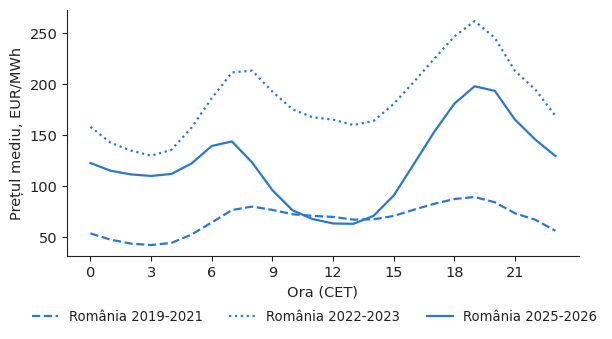

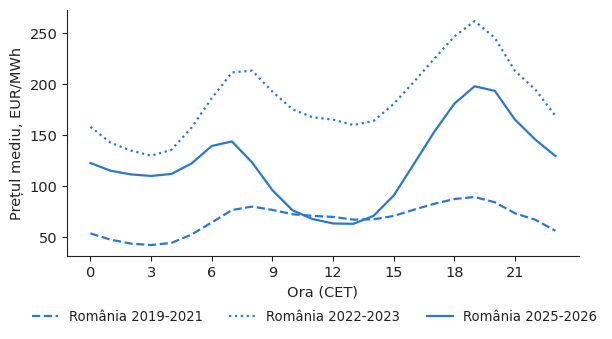

In [2]:
ph = cu.prices_hourly()[["RO", "BG", "HU"]].loc["2018-01-01":"2026-10-31"]
loc = ph.index.tz_convert("Europe/Brussels")                  # CET hours, as in the day-ahead auction
ph = ph.set_axis(loc.tz_localize(None))
ph = ph[~ph.index.duplicated()]
day = ph.index.normalize(); hr = ph.index.hour
D = {z: ph[z].groupby([day, hr]).mean().unstack() for z in ["RO", "BG", "HU"]}   # day x 24 matrices (EUR/MWh)
for z in D:
    D[z] = D[z].dropna()
common = D["RO"].index.intersection(D["BG"].index).intersection(D["HU"].index)
D = {z: D[z].loc[common] for z in D}
print("days with 24 prices in RO, BG and HU:", len(common), common.min().date(), "-", common.max().date())
def fig_shape(lang):
    fig, ax = plt.subplots(figsize=(6.6, 3.2))
    for per, ls, lab in [(("2019", "2021"), "--", ("2019-2021", "2019-2021")), (("2022", "2023"), ":", ("2022-2023", "2022-2023")), (("2025", "2026"), "-", ("2025-2026", "2025-2026"))]:
        m = D["RO"].loc[per[0]:per[1]].mean()
        ax.plot(m.index, m.values, color=cu.PAL["RO"], ls=ls, lw=1.6, label=cu.T(lang, "Romania ", "România ") + lab[0])
    ax.set_xlabel(cu.T(lang, "Hour (CET)", "Ora (CET)")); ax.set_ylabel(cu.T(lang, "Mean price, EUR/MWh", "Prețul mediu, EUR/MWh")); ax.set_xticks(range(0, 24, 3))
    cu.legend_bottom(fig, ncol=3)
    return fig
cu.save_both(fig_shape, "f1_daily_shape")

## 2. Prognoze probabilistice pentru cele 24 de prețuri din ziua următoare

In [3]:
from sklearn.ensemble import RandomForestRegressor
Y = D["RO"].values                       # target: the 24-hour price vector of day d
days_ = D["RO"].index
def feats(i):
    """Information available on day d-1 at noon: prices of d-1 (all hours known since the d-1 auction), of d-7, neighbours' means, calendar."""
    d = days_[i]
    return np.r_[Y[i - 1], Y[i - 7], D["BG"].values[i - 1].mean(), D["HU"].values[i - 1].mean(),
                 d.dayofweek, d.month, np.sin(2 * np.pi * d.dayofyear / 365.25), np.cos(2 * np.pi * d.dayofyear / 365.25)]
Xall = np.array([feats(i) if i >= 7 else np.full(24 * 2 + 6, np.nan) for i in range(len(days_))])
WIN, BLOCK = 365, 30                     # paper: 365-day training window, re-fitted every 30-day block
start = int(np.searchsorted(days_, pd.Timestamp("2019-01-08")))
QL = [0.1, 0.5, 0.9]
quant = np.full((len(days_), 24, len(QL)), np.nan); mean_fc = np.full((len(days_), 24), np.nan); crps = np.full((len(days_), 24), np.nan)
for b0 in range(start, len(days_), BLOCK):
    tr = np.arange(max(7, b0 - WIN), b0); te = np.arange(b0, min(b0 + BLOCK, len(days_)))
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=15, max_features=0.33, random_state=0, n_jobs=-1).fit(Xall[tr], Y[tr])
    leaf_tr = rf.apply(Xall[tr]); leaf_te = rf.apply(Xall[te])
    for k, i in enumerate(te):
        same = (leaf_tr == leaf_te[k])                                   # n_train x n_trees
        w = (same / same.sum(axis=0)).mean(axis=1)                       # forest weights w_i(x): a distribution over training DAYS
        ytr = Y[tr]
        mean_fc[i] = w @ ytr
        for h in range(24):
            o = np.argsort(ytr[:, h]); cw = np.cumsum(w[o])
            quant[i, h] = [ytr[o, h][min(np.searchsorted(cw, q), len(o) - 1)] for q in QL]
            yy = Y[i, h]
            crps[i, h] = w @ np.abs(ytr[:, h] - yy) - 0.5 * w @ np.abs(ytr[:, h][:, None] - ytr[:, h][None, :]) @ w
ok = ~np.isnan(mean_fc[:, 0])
paper_win = ok & (days_ <= "2024-09-30")
fc_acc = {"MAE": np.nanmean(np.abs(Y[paper_win] - mean_fc[paper_win])), "RMSE": np.sqrt(np.nanmean((Y[paper_win] - mean_fc[paper_win]) ** 2)),
          "CRPS": np.nanmean(crps[paper_win]), "cover80": 100 * np.mean((Y[paper_win] >= quant[paper_win, :, 0]) & (Y[paper_win] <= quant[paper_win, :, 2]))}
naive_mae = np.nanmean(np.abs(Y[paper_win] - Y[np.where(paper_win)[0] - 1]))
print("RO, 8 Jan 2019 - 30 Sep 2024:", {k: round(v, 2) for k, v in fc_acc.items()}, "| naive (yesterday) MAE %.2f" % naive_mae)
print("paper (DRF, RO, same window): MAE 39.63, RMSE 49.60, CRPS 28.12")

RO, 8 Jan 2019 - 30 Sep 2024: {'MAE': np.float64(26.5), 'RMSE': np.float64(48.46), 'CRPS': np.float64(19.71), 'cover80': np.float64(80.85)} | naive (yesterday) MAE 25.59
paper (DRF, RO, same window): MAE 39.63, RMSE 49.60, CRPS 28.12


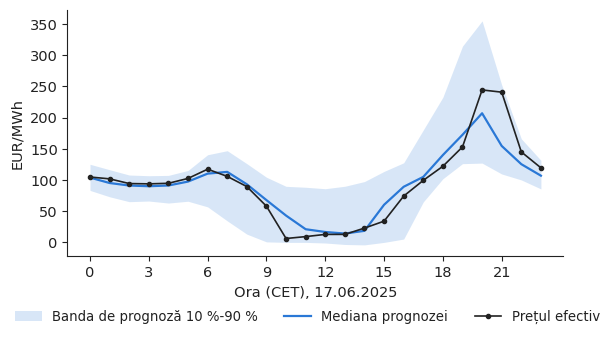

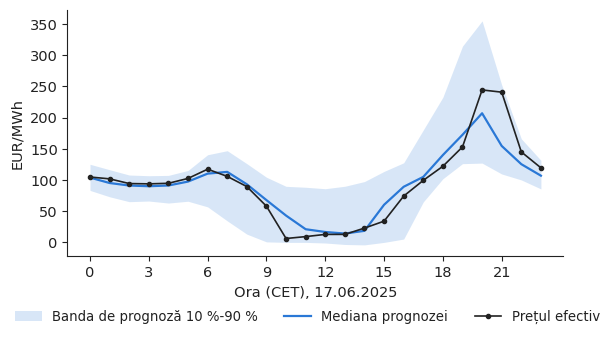

In [4]:
i_ex = int(np.searchsorted(days_, pd.Timestamp("2025-06-17")))
def fig_fan(lang):
    fig, ax = plt.subplots(figsize=(6.4, 3.2))
    hrs = np.arange(24)
    ax.fill_between(hrs, quant[i_ex, :, 0], quant[i_ex, :, 2], color=cu.PAL["RO"], alpha=0.18, lw=0, label=cu.T(lang, "10 %-90 % forecast band", "Banda de prognoză 10 %-90 %"))
    ax.plot(hrs, quant[i_ex, :, 1], color=cu.PAL["RO"], lw=1.6, label=cu.T(lang, "Forecast median", "Mediana prognozei"))
    ax.plot(hrs, Y[i_ex], color=cu.INK, lw=1.2, marker="o", ms=3, label=cu.T(lang, "Actual price", "Prețul efectiv"))
    ax.set_xlabel(cu.T(lang, "Hour (CET), ", "Ora (CET), ") + f"{days_[i_ex]:%d.%m.%Y}"); ax.set_ylabel("EUR/MWh"); ax.set_xticks(range(0, 24, 3))
    cu.legend_bottom(fig, ncol=3)
    return fig
cu.save_both(fig_fan, "f2_forecast_fan")

## 3. Strategiile de tranzacționare

In [5]:
ETA = 0.9                                         # round-trip efficiency applied as in the paper: profit = -p_buy/ETA + ETA*p_sell (1 MWh)
pairs = [(a, b) for a in range(24) for b in range(a + 1, 24)]
def pf_daily(P):                                  # perfect foresight: best pair each day, ex post (upper bound)
    return np.array([max(0.0, max(ETA * p[b] - p[a] / ETA for a, b in pairs)) for p in P])
def fixed_pair(P, P_sel):                         # one fixed (h1, h2), chosen EX ANTE on an earlier period P_sel (paper's NH idea)
    tot = {(a, b): (ETA * P_sel[:, b] - P_sel[:, a] / ETA).sum() for a, b in pairs}
    a, b = max(tot, key=tot.get)
    return ETA * P[:, b] - P[:, a] / ETA, (a, b)    # trades every day: whether a day pays off is not known in advance
def quantile_based(P, Q, alpha):
    """Simplified version of the paper's quantile-based rule: pick h1<h2 maximising the median spread; trade only if positive;
    limit bids: buy at the (1-q) quantile of h1, sell at the q quantile of h2, q=(1-alpha)/2.
    Battery: empty or full (1 MWh). If the buy clears but the sell does not, the battery stays full and sells at the next day's
    highest-median hour at any price (market order) - a simplified reset rule."""
    q = (1 - alpha) / 2
    full, prof, both = False, [], []
    for p, qq in zip(P, Q):
        med = qq[:, 1]
        if full:                                                     # reset: empty the battery first
            hs = int(np.argmax(med)); prof.append(ETA * p[hs]); full = False; both.append(False); continue
        a, b = max(pairs, key=lambda ab: ETA * med[ab[1]] - med[ab[0]] / ETA)
        if ETA * med[b] - med[a] / ETA <= 0:
            prof.append(0.0); both.append(False); continue
        bid_buy = np.interp(1 - q, QL, qq[a]); bid_sell = np.interp(q, QL, qq[b])   # quantiles interpolated between 10 %, 50 %, 90 %
        bought = p[a] <= bid_buy; sold = bought and p[b] >= bid_sell
        pi = 0.0
        if bought:
            pi -= p[a] / ETA
            if sold:
                pi += ETA * p[b]
            else:
                full = True
        prof.append(pi); both.append(bool(bought and sold))
    return np.array(prof), np.mean(both)

In [6]:
def evaluate(mask, sel_mask, label):
    P = Y[mask]; Qm = quant[mask]
    out = {}
    out["Perfect foresight (daily)"] = (pf_daily(P), np.nan)
    nh, pair = fixed_pair(P, Y[sel_mask]); out[f"Fixed hours {pair[0]:02d}->{pair[1]:02d}"] = (nh, np.nan)
    for a_ in [0.0, 0.4, 0.8]:
        out[f"Forecast-based, alpha={a_}"] = quantile_based(P, Qm, a_)
    return out, pair
CAPEX, L_, R_ = 500_000, 15, 0.07                 # paper's battery assumptions (EUR, years, discount rate)
ann_f = sum(1 / (1 + R_) ** t for t in range(1, L_ + 1))
def invest(pi):
    pa = 365 * pi.mean()
    return {"cum_profit": pi.sum(), "profit_year": pa, "NPV": -CAPEX + pa * ann_f, "payback": CAPEX / pa if pa > 0 else np.inf, "breakeven_capex": 15 * pa}
# fixed hours chosen ex ante: on the 365 days before each evaluation window (the 365 days before 8 Jan 2019 for the paper's window, 2024 for the extension)
SEL_PAPER = (days_ >= pd.Timestamp("2019-01-08") - pd.Timedelta(days=365)) & (days_ < "2019-01-08")
SEL_NEW = (days_ >= "2024-01-01") & (days_ <= "2024-12-31")
res_paper, pair_paper = evaluate(ok & (days_ <= "2024-09-30"), SEL_PAPER, "2019-2024")
res_new, pair_new = evaluate(ok & (days_ >= "2025-01-01"), SEL_NEW, "2025-2026")
tab = pd.DataFrame({k: {**invest(v[0]), "both_accepted": 100 * v[1]} for k, v in res_paper.items()}).T
tab_new = pd.DataFrame({k: invest(v[0]) for k, v in res_new.items()}).T
print("Romania, 8 Jan 2019 - 30 Sep 2024 (the paper's test window):")
display(cu.show_table(tab, best={"cum_profit": "max", "NPV": "max"}, digits=0))
print("Romania, 2025 - Oct 2026 (extension):")
display(cu.show_table(tab_new, best={"cum_profit": "max", "NPV": "max"}, digits=0))

Romania, 8 Jan 2019 - 30 Sep 2024 (the paper's test window):


,cum_profit,profit_year,NPV,payback,breakeven_capex,both_accepted
Perfect foresight (daily),189816,33197,-197642,15,497960,nan
Fixed hours 03->19,130324,22793,-292406,22,341890,nan
"Forecast-based, alpha=0.0",68333,11951,-391152,42,179263,15
"Forecast-based, alpha=0.4",103163,18042,-335672,28,270635,43
"Forecast-based, alpha=0.8",126569,22136,-298388,23,332039,76


Romania, 2025 - Oct 2026 (extension):


,cum_profit,profit_year,NPV,payback,breakeven_capex
Perfect foresight (daily),96190,52717,-19859,9,790754
Fixed hours 12->19,71976,39447,-140724,13,591698
"Forecast-based, alpha=0.0",40721,22317,-296736,22,334760
"Forecast-based, alpha=0.4",59770,32757,-201653,15,491353
"Forecast-based, alpha=0.8",74552,40858,-127870,12,612868


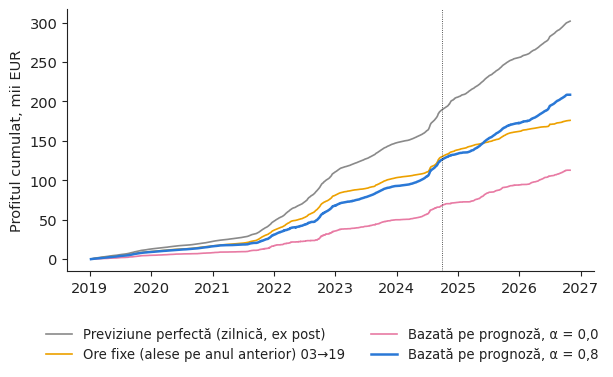

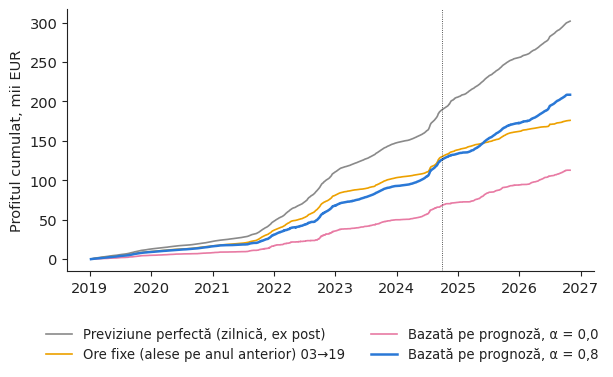

In [7]:
def lbl(k):
    if k.startswith("Perfect"):
        return ("Perfect foresight (daily, ex post)", "Previziune perfectă (zilnică, ex post)")
    if k.startswith("Fixed"):
        k2 = k.replace("->", "$\\rightarrow$")
        return (k2.replace("Fixed hours", "Fixed hours (chosen on the previous year)"), k2.replace("Fixed hours", "Ore fixe (alese pe anul anterior)"))
    a_ = k.split("=")[1]
    return (f"Forecast-based, $\\alpha$ = {a_}", f"Bazată pe prognoză, $\\alpha$ = {a_.replace('.', ',')}")
t = tab[["cum_profit", "profit_year", "NPV", "payback", "both_accepted"]].copy()
t["new_year"] = tab_new["profit_year"].values
t.index = [lbl(k) for k in t.index]
cu.write_table(t, "strategies", header=[("Strategy (1 MW / 1 MWh, Romania)", "Strategia (1 MW / 1 MWh, România)"), ("Profit 2019--24, EUR", "Profitul 2019--24, EUR"),
               ("EUR/year", "EUR/an"), ("NPV, EUR", "VAN, EUR"), ("Payback, yrs", "Perioada de recuperare, ani"), ("Both bids, \\%", "Ambele oferte acceptate, \\%"),
               ("EUR/year 2025--26", "EUR/an 2025--26")],
               digits={"cum_profit": 0, "profit_year": 0, "NPV": 0, "payback": 1, "both_accepted": 1, "new_year": 0},
               best={"profit_year": "max", "NPV": "max", "payback": "min", "new_year": "max"})
cols = {"Perfect": cu.MUTED, "Fixed": cu.PAL["BG"], "0.0": cu.PAL["c5"], "0.4": cu.PAL["c7"], "0.8": cu.PAL["RO"]}
def col(k):
    return cols["Perfect"] if k.startswith("Perfect") else cols["Fixed"] if k.startswith("Fixed") else cols[k.split("=")[1]]
dd = days_[ok]
allres, _ = evaluate(ok, SEL_PAPER, "all")
def fig_cum(lang):
    fig, ax = plt.subplots(figsize=(6.8, 3.4))
    for k, v in allres.items():
        if k.endswith("0.4"):
            continue
        ax.plot(dd, np.cumsum(v[0]) / 1000, color=col(k), lw=1.8 if k.endswith("0.8") else 1.2, label=cu.T(lang, *lbl(k)).replace("$\\alpha$", "α").replace("$\\rightarrow$", "→"))
    ax.axvline(pd.Timestamp("2024-09-30"), color=cu.INK, lw=0.6, ls=":")
    ax.set_ylabel(cu.T(lang, "Cumulative profit, thousand EUR", "Profitul cumulat, mii EUR"))
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_cum, "f3_cumulative_profit", headline=True)

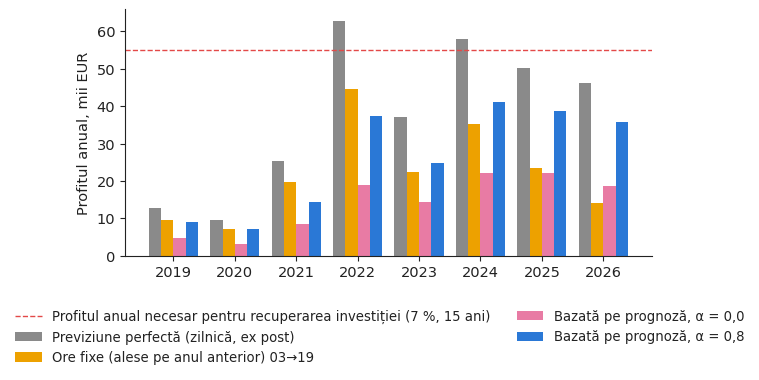

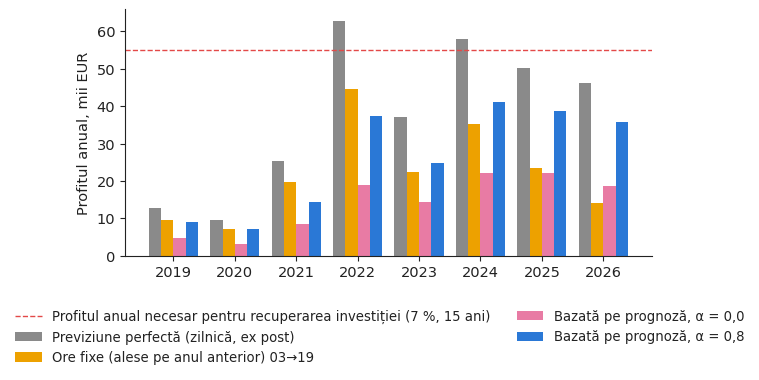

In [8]:
yrs = pd.Index(dd.year)
by_year = pd.DataFrame({k: pd.Series(v[0], index=dd).groupby(yrs).sum() for k, v in allres.items() if not k.endswith("0.4")})
def fig_year(lang):
    fig, ax = plt.subplots(figsize=(6.8, 3.2))
    ks = list(by_year.columns); w = 0.8 / len(ks)
    for j, k in enumerate(ks):
        ax.bar(by_year.index + (j - len(ks) / 2 + 0.5) * w, by_year[k] / 1000, width=w, color=col(k), label=cu.T(lang, *lbl(k)).replace("$\\alpha$", "α").replace("$\\rightarrow$", "→"))
    ax.axhline(CAPEX / ann_f / 1000, color=cu.EVENT, ls="--", lw=1, label=cu.T(lang, "Annual profit needed to repay CAPEX (7 %, 15 years)", "Profitul anual necesar pentru recuperarea investiției (7 %, 15 ani)"))
    ax.set_ylabel(cu.T(lang, "Profit per year, thousand EUR", "Profitul anual, mii EUR")); ax.set_xticks(by_year.index)
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_year, "f4_profit_by_year")

## 4. Arbitrajul transfrontalier: cumpărare într-o zonă și vînzare în alta

In [9]:
# Perfect-foresight and fixed-route cross-zone arbitrage (before cross-border fees and capacity limits)
Z = ["RO", "BG", "HU"]
Pz = {z: D[z].values[ok & (days_ <= "2024-09-30")] for z in Z}
best_cross = np.zeros(len(Pz["RO"])); route = []
for i in range(len(best_cross)):
    v, r_ = 0.0, None
    for zb in Z:
        for zs in Z:
            for a, b in pairs:
                g = ETA * Pz[zs][i, b] - Pz[zb][i, a] / ETA
                if g > v:
                    v, r_ = g, (zb, zs)
    best_cross[i] = v; route.append(r_)
pf_single = pf_daily(Pz["RO"])
gain_cross = 100 * (best_cross.sum() / pf_single.sum() - 1)
routes = pd.Series([f"{a}->{b}" for a, b in [r for r in route if r] if a != b]).value_counts()
share_cross = 100 * np.mean([r is not None and r[0] != r[1] for r in route])
print("perfect-foresight profit RO only: %.0f EUR; best of RO/BG/HU routes: %.0f EUR (+%.1f %%)" % (pf_single.sum(), best_cross.sum(), gain_cross))
print(routes.head(5))

perfect-foresight profit RO only: 189816 EUR; best of RO/BG/HU routes: 210142 EUR (+10.7 %)
BG->RO    317
HU->RO    306
RO->HU    294
BG->HU    212
RO->BG    117
Name: count, dtype: int64


In [10]:
k08 = "Forecast-based, alpha=0.8"; nh_key = [k for k in tab.index if k.startswith("Fixed")][0]
cu.write_numbers({
    "nDays": int(paper_win.sum()), "maeRF": fc_acc["MAE"], "rmseRF": fc_acc["RMSE"], "crpsRF": fc_acc["CRPS"], "coverRF": fc_acc["cover80"], "maeNaive": naive_mae,
    "pfCum": tab.loc["Perfect foresight (daily)", "cum_profit"], "nhCum": tab.loc[nh_key, "cum_profit"], "qbCum": tab.loc[k08, "cum_profit"],
    "qbYear": tab.loc[k08, "profit_year"], "pfYear": tab.loc["Perfect foresight (daily)", "profit_year"], "nhYear": tab.loc[nh_key, "profit_year"],
    "qbNPV": tab.loc[k08, "NPV"], "pfNPV": tab.loc["Perfect foresight (daily)", "NPV"], "qbPay": tab.loc[k08, "payback"], "pfPay": tab.loc["Perfect foresight (daily)", "payback"],
    "qbBoth": tab.loc[k08, "both_accepted"], "qbVsNh": 100 * (tab.loc[k08, "cum_profit"] / tab.loc[nh_key, "cum_profit"] - 1),
    "qbZero": tab.loc["Forecast-based, alpha=0.0", "cum_profit"],
    "nhPair": f"{pair_paper[0]:02d}:00$\\rightarrow${pair_paper[1]:02d}:00", "nhPairNew": f"{pair_new[0]:02d}:00$\\rightarrow${pair_new[1]:02d}:00",
    "qbYearNew": tab_new.loc[k08, "profit_year"], "pfYearNew": tab_new.loc["Perfect foresight (daily)", "profit_year"],
    "qbNPVNew": tab_new.loc[k08, "NPV"], "qbPayNew": tab_new.loc[k08, "payback"],
    "needYear": CAPEX / ann_f, "crossGain": gain_cross, "topRoute": routes.index[0].replace("->", "$\\rightarrow$"), "topRouteShare": 100 * routes.iloc[0] / routes.sum(), "shareCross": share_cross,
}, digits={"maeRF": 2, "rmseRF": 2, "crpsRF": 2, "coverRF": 1, "maeNaive": 2, "pfCum": 0, "nhCum": 0, "qbCum": 0, "qbYear": 0, "pfYear": 0, "nhYear": 0,
           "qbNPV": 0, "pfNPV": 0, "qbPay": 1, "pfPay": 1, "qbBoth": 1, "qbVsNh": 1, "qbZero": 0, "qbYearNew": 0, "pfYearNew": 0, "qbNPVNew": 0,
           "qbPayNew": 1, "needYear": 0, "crossGain": 1, "topRouteShare": 1, "shareCross": 1})

In [11]:
# slide-ready summary for the lecture box "Research from our group" (max 6 lines), both languages; every number comes from this notebook
for lang in ("en", "ro"):
    F = lambda v, nd=1: cu.fmt(float(v), nd, lang)
    t = lambda en, ro: ro if lang == "ro" else en
    pf = tab.loc["Perfect foresight (daily)"]; nh = tab.loc[nh_key]; qb = tab.loc[k08]
    lines = [
        t("\\textbf{Battery arbitrage with probabilistic forecasts} (Andrei, Cepoi, Dumitrescu, Lessmann, Chiriac, Pele \\& Petukhina, 2026, SSRN): DRF-based bidding beats fixed hours in RO, BG, HU, CZ, but no strategy repays a 500k EUR battery (Section~6.2).",
          "\\textbf{Arbitrajul cu baterii și prognozele probabilistice} (Andrei, Cepoi, Dumitrescu, Lessmann, Chiriac, Pele și Petukhina, 2026, SSRN): ofertele bazate pe DRF depășesc strategia cu ore fixe în RO, BG, HU și CZ, dar nicio strategie nu recuperează o investiție de 500 de mii EUR într-o baterie (secțiunea~6.2)."),
        t(f"Our replication (RO, 2019--Sep 2024): perfect foresight {F(pf.cum_profit / 1e3)}k EUR (paper 188.2k), fixed hours chosen on the previous year {F(nh.cum_profit / 1e3)}k (paper 133.2k).",
          f"Replicarea noastră (RO, 2019--sept.\\ 2024): previziune perfectă {F(pf.cum_profit / 1e3)} mii EUR (lucrarea: 188,2 mii), ore fixe alese pe anul anterior {F(nh.cum_profit / 1e3)} mii EUR (lucrarea: 133,2 mii)."),
        t(f"Realistic strategy: {F(qb.profit_year / 1e3)}k EUR/year vs {F(CAPEX / ann_f / 1e3)}k needed; {F(tab_new.loc[k08, 'profit_year'] / 1e3)}k/year in 2025--26 as solar middays deepen.",
          f"Strategia realistă: {F(qb.profit_year / 1e3)} mii EUR/an, față de cele {F(CAPEX / ann_f / 1e3)} mii EUR/an necesare; {F(tab_new.loc[k08, 'profit_year'] / 1e3)} mii EUR/an în 2025--26, cînd prețurile de la prînz sînt și mai scăzute din cauza producției solare."),
        t("Decision: value storage on forecast-driven profits and stacked revenues, never on perfect foresight.",
          "Decizia: evaluați stocarea după profitul strategiilor bazate pe prognoze și după veniturile cumulate din mai multe surse, niciodată după previziunea perfectă."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{Battery arbitrage with probabilistic forecasts} (Andrei, Cepoi, Dumitrescu, Lessmann, Chiriac, Pele \& Petukhina, 2026, SSRN): DRF-based bidding beats fixed hours in RO, BG, HU, CZ, but no strategy repays a 500k EUR battery (Section~6.2).
  \item Our replication (RO, 2019--Sep 2024): perfect foresight 189.8k EUR (paper 188.2k), fixed hours chosen on the previous year 130.3k (paper 133.2k).
  \item Realistic strategy: 22.1k EUR/year vs 54.9k needed; 40.9k/year in 2025--26 as solar middays deepen.
  \item Decision: value storage on forecast-driven profits and stacked revenues, never on perfect foresight.
\end{itemize}



## Exerciții suplimentare
1. Permiteți două cicluri pe zi (noapte–prînz și prînz–seară). Cu cît crește profitul în 2025–2026, cînd energia de la prînz este ieftină datorită producției solare?
2. Refaceți calculele pentru un CAPEX de 250.000 EUR (intervalul de echilibru din lucrare este 48 %–75 % din valoarea de referință). Ce strategii devin viabile?
3. Adăugați o regulă transfrontalieră bazată pe prognoză (alegeți zona de cumpărare și zona de vînzare pe baza medianelor prognozate). De ce este cîștigul realizat mai mic decît în ipoteza previziunii perfecte?